In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import warnings
import os 
from pathlib import Path

import zarr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import matplotlib.colors as mcolors
from matplotlib import gridspec
import seaborn as sns
from dotenv import dotenv_values

from hm3d_utils.plotting import plot_clusters_collapsed, plot_single_cluster


In [3]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Fig_02"
os.makedirs(OUTDIR, exist_ok=True)

ST_FP = DATADIR / "9_objects" / "spatial" / 'hypomap3d_spatial_voxel_level.zarr'

In [4]:
store = zarr.open(ST_FP, mode='r')

### Plot all target L2 clusters

In [5]:
cluster_color_map = {
    'Gb2-63': "#ff7f0e", 
    'Gb2-56': "#1f77b4", 
    "Gb2-68": "#2ca02c"
}

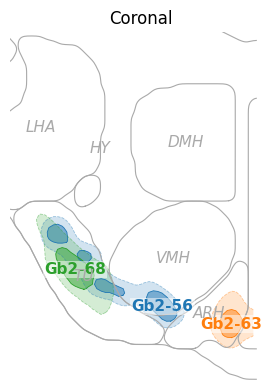

In [8]:
# Coronal view - sum over AP range, plot [DV, LM]
plot_clusters_collapsed(store, 
    cluster_color_map.keys(), 
    slice_range=(80, 130),
    thresholds     = [0.7, 0.9],    
    regions=['HY', 'ARH', 'DMH', 'VMH', 'LHA','TU'], 
    view='coronal',
    alphas         = [0.2, 0.5],
    linestyles = ['dashed', 'solid'],
    linewidths = [0.6,0.6],  
    axis0_range    = (60, 140)  ,
    axis1_range    = (50, 110)  ,
    figsize        = (4,4),
    label_fontsize = 11,
   region_label_fontsize = 11,
   title="Coronal",
   color_mapping = cluster_color_map,
   save_path = OUTDIR / "OtpSix_coronal.pdf"
)


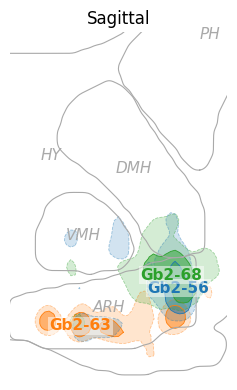

In [9]:
# Coronal view - sum over AP range, plot [DV, LM]
plot_clusters_collapsed(store, 
    cluster_color_map.keys(), 
    slice_range=(80, 130),
    thresholds     = [0.7, 0.9],
    regions= ['HY', 'ARH', 'DMH', 'VMH','AHN','PH'],
    view='sagittal',
    alphas         = [0.2, 0.5],
    linestyles = ['dashed', 'solid'],
    linewidths = [0.6,0.6],  
    axis0_range    = (60, 140)  ,
    axis1_range    = (80, 130)  ,
    figsize        = (4,4),
    label_fontsize = 11  ,
   region_label_fontsize = 11,
   title="Sagittal",
   color_mapping = cluster_color_map,
   save_path = OUTDIR / "OtpSix_sagittal.pdf"
)